# Issue #291 — decomposed rare-event value heads

This notebook evaluates complete-ticket hit probability, conditional winning
gross and direct-P&L ranking. Beijing issue is the independent unit. OOF covers
2019–2023 and 2024+ remains sealed.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
ART = ROOT / 'docs/research/artifacts/issue-291'
summary = pd.read_csv(ART / 'model_summary.csv')
ranking = pd.read_csv(ART / 'ranking_summary.csv')
annual = pd.read_csv(ART / 'ranking_annual.csv')
paths = pd.read_csv(ART / 'ranking_issue_paths.csv')
actions = pd.read_csv(ART / 'candidate_action_distribution.csv')
receipt = json.loads((ART / 'analysis_receipt.json').read_text())
assert receipt['sealed_years_opened'] == []
receipt

{'contract': 'BJ-UNIFIED-RARE-EVENT-VALUE-001/analysis-v1',
 'independent_unit': 'BEIJING_ISSUE',
 'sealed_years_opened': [],
 'input_sha256': {'oof_receipt': '36a991bc6ace8d0579c57f9887a60fb0925bd9c1da68c2204c782e855378c1ec',
  'model_metrics': '4096b4cba0f4641a9b10b17c3ca4d448835e77af119034382d466236109a623a',
  'ranking_metrics': '6f3aa512ea6e7e04424bd1648d57e89a6e777c3b1ca6b64bbfbd2c1259fc671a',
  'ranking_issue_paths': 'c98c34c88efac2bc49681085260580bc63d7c0b7ce796baca0a7f27f6ab36c6b',
  'ranking_selected_tickets': '4765e6f3293727387b50708062849c6534f9d2ba66f199ceb78cbbc84d97a160'},
 'output_sha256': {'model_summary': 'ea489870d4f6173ce009ee8f32c90f136722bd4605f95f331e8d9767afcc76ac',
  'ranking_summary': '38ab08a1082ed58a4846ea468a9fb832129f66523d97cf167f50ebfd1ec713c5',
  'ranking_annual': '231e1d93d7a2cb4b2ae616da04424631aacfb74c530e648c8c36fe48e9464871',
  'ranking_paths': 'dac3b77a70ca0232781b5cc16a5c93e7e250af0aa5d6251357c6491f7a1e12e1',
  'reliability': 'd32de50bf4172647d79

## Probability and payoff heads

In [2]:
summary[['domain','model','event_rate','average_precision',
         'average_precision_lift','conditional_gross_mae_cny']]

,domain,model,event_rate,average_precision,average_precision_lift,conditional_gross_mae_cny
0,BASE,ACTION_LOGIT_RIDGE,0.000570,0.001046,1.835599,1761.729498
1,BASE,DATA_HGB,0.000570,0.000964,1.692470,1403.238859
2,BASE,DATA_LOGIT_RIDGE,0.000570,0.002041,3.583634,1997.440048
3,PROTECTION,ACTION_LOGIT_RIDGE,0.000342,0.000630,1.843686,2780.867796
4,PROTECTION,DATA_HGB,0.000342,0.000615,1.799451,2258.522558
5,PROTECTION,DATA_LOGIT_RIDGE,0.000342,0.000976,2.856015,2259.598670


Probability ranking contains modest Data signal, especially in the
linear model. Conditional-gross error remains large, so the decomposed expected
value head is not automatically the best economic ranker.

## Same-budget base-ticket comparison

In [3]:
ranking.loc[
    ranking.domain.eq('BASE') & ranking.ticket_budget_per_issue.eq(64),
    ['model','score','hits','pnl_cny','global_ex_largest_issue_pnl_cny',
     'bootstrap_roi_p025','bootstrap_roi_p975','positive_years',
     'max_drawdown_pct','longest_losing_issue_streak']
].sort_values('pnl_cny', ascending=False)

,model,score,hits,pnl_cny,global_ex_largest_issue_pnl_cny,bootstrap_roi_p025,bootstrap_roi_p975,positive_years,max_drawdown_pct,longest_losing_issue_streak
23,CONTROL,UNATTAINABLE_ORACLE,153,555999.760633,513846.233583,1134.487929,2174.015177,5,0.333201,5
43,DATA_LOGIT_RIDGE,DIRECT_PNL,8,103270.260983,61116.733932,-2.369639,704.463147,4,9.710738,112
31,DATA_HGB,DIRECT_PNL,10,56489.387674,21689.939505,-22.728583,432.732514,3,12.485265,90
27,DATA_HGB,DECOMPOSED_EV,4,49366.946908,14567.498739,-85.787019,471.290194,3,12.834024,139
3,ACTION_LOGIT_RIDGE,DECOMPOSED_EV,4,23458.369351,-10924.915802,-89.072197,326.073158,3,15.384643,159
39,DATA_LOGIT_RIDGE,DECOMPOSED_EV,2,4973.098636,-29410.186517,-100.000000,229.116759,2,20.463536,211
47,DATA_LOGIT_RIDGE,HIT_PROBABILITY,27,-12606.513383,-14429.942214,-60.726104,-10.307974,1,13.405828,30
7,ACTION_LOGIT_RIDGE,DIRECT_PNL,3,-12983.425739,-22804.679621,-100.000000,45.900649,2,16.749163,128
11,ACTION_LOGIT_RIDGE,HIT_PROBABILITY,20,-14400.997229,-17446.948778,-70.712862,-8.711958,1,14.537526,61
15,CONTROL,MARKET_PRODUCT,23,-15211.253270,-17034.682100,-67.048799,-18.640943,0,15.986745,55


## Candidate yearly and issue-level capital path

In [4]:
annual.loc[
    annual.domain.eq('BASE') & annual.model.eq('DATA_LOGIT_RIDGE') &
    annual.score.eq('DIRECT_PNL') & annual.ticket_budget_per_issue.eq(64)
][['oof_year','tickets','hits','gross_cny','pnl_cny']]

,oof_year,tickets,hits,gross_cny,pnl_cny
35,2019,3392,4,74167.567955,67383.567955
83,2020,2432,1,4893.813483,29.813483
131,2021,4032,0,0.000000,-8064.000000
179,2022,3968,2,43918.269906,35982.269906
227,2023,3392,1,14722.609639,7938.609639


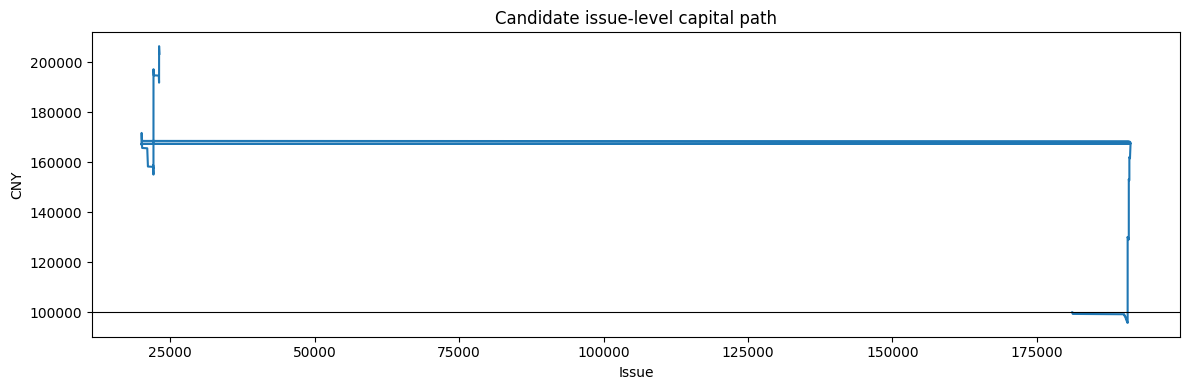

In [5]:
candidate = paths.loc[
    paths.domain.eq('BASE') & paths.model.eq('DATA_LOGIT_RIDGE') &
    paths.score.eq('DIRECT_PNL') & paths.ticket_budget_per_issue.eq(64)
].sort_values(['oof_year','issue_numeric'])
ax = candidate.plot(x='issue', y='capital_cny', figsize=(12,4), legend=False)
ax.axhline(100_000, color='black', linewidth=.8)
ax.set(title='Candidate issue-level capital path', ylabel='CNY', xlabel='Issue')
plt.tight_layout()

## Learned parameter distribution

In [6]:
actions.groupby(['n','k'], as_index=False).agg(
    tickets=('tickets','sum'), hits=('hits','sum'), pnl_cny=('pnl_cny','sum')
)

,n,k,tickets,hits,pnl_cny
0,7,16,1322,1,3396.196946
1,7,64,994,2,4542.556338
2,8,16,1113,0,-2226.000000
3,8,64,1040,2,31536.085856
4,9,16,5331,0,-10662.000000
5,9,64,7416,3,76683.421842


## Protection falsifier

In [7]:
ranking.loc[
    ranking.domain.eq('PROTECTION') & ranking.ticket_budget_per_issue.eq(64),
    ['model','score','hits','pnl_cny','global_ex_largest_issue_pnl_cny',
     'bootstrap_roi_p025','positive_years']
].sort_values('pnl_cny', ascending=False)

,model,score,hits,pnl_cny,global_ex_largest_issue_pnl_cny,bootstrap_roi_p025,positive_years
75,CONTROL,UNATTAINABLE_ORACLE,798,5.007535e+06,4.877448e+06,12996.480101,5
83,DATA_HGB,DIRECT_PNL,3,2.721625e+04,-1.855578e+03,-100.000000,1
87,DATA_HGB,HIT_PROBABILITY,13,3.969952e+03,-3.094161e+03,-53.156118,2
63,CONTROL,ADVERSE_DIVERGENCE,5,3.467978e+03,-1.425910e+04,-92.311924,2
51,ACTION_LOGIT_RIDGE,DECOMPOSED_EV,1,3.346672e+03,-3.430400e+04,-100.000000,1
79,DATA_HGB,DECOMPOSED_EV,1,-1.118488e+03,-3.430400e+04,-100.000000,1
71,CONTROL,RANDOM,3,-6.348828e+03,-2.349256e+04,-100.000000,1
59,ACTION_LOGIT_RIDGE,HIT_PROBABILITY,13,-1.184947e+04,-1.489542e+04,-69.728055,1
99,DATA_LOGIT_RIDGE,HIT_PROBABILITY,26,-1.365657e+04,-1.547999e+04,-63.510718,0
67,CONTROL,MARKET_PRODUCT,23,-1.521125e+04,-1.703468e+04,-67.048799,0


## Decision

Protection remains NO_PROMOTION. The base DATA_LOGIT_RIDGE direct-P&L Top-64
path is retained as a candidate signal because it is positive ex-largest and in
four OOF years, including 2023. Its bootstrap lower bound remains slightly
negative and its longest losing streak is 112 issues, so #292 must confirm the
signal with nuisance replicas and explicit cash/baseline competition before any
held-out or funding decision.